<a href="https://colab.research.google.com/github/hombremono873/Cuadernos_colab/blob/main/Modelos_vivienda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Entrega 2**

### **Universidad Santo Tomás**
**Especialización / Maestría:** Análisis de datos y sistemas inteligentes  

---

* **Fecha:** 25 de octubre del 2026
* **Estudiantes:**
  * Omar Alberto Torres
  * Diego Alejandro Roa Lara
* **Docente:** Gerardo Humberto Valencia Rivera

# **Predicción del precio de viviendas en California**
**Objetivo:** predecir **median_house_value** con tres modelos (Regresión, Random Forest y Red Neuronal) y superar un R² de 0.70 en el conjunto de prueba.

**Etapas:** carga__exploración __división__limpieza y nuevas características __ escalado__modelos__comparación.

### **Definición del Problema y Variable Objetivo**

1. Formulación del problema: El objetivo de este proyecto es resolver un problema de aprendizaje supervisado de tipo regresión. Utilizando diversas características demográficas, geográficas y físicas de diferentes distritos de California, buscamos entrenar modelos predictivos capaces de estimar con precisión el costo de la vivienda. Esto nos permitirá entender qué factores influyen más en el valor del sector inmobiliario.

2. Variable objetivo: La variable que deseamos predecir es median_house_value (Valor medio de la vivienda). Representa la mediana del valor de las viviendas en cada distrito, expresada en dólares americanos. Al ser una variable numérica continua, evaluaremos el desempeño de los modelos a través de métricas de regresión como el coeficiente de determinación R2 y el error cuadrático medio RMSE.

# **Celda 1: Librerías**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error

# **Celda 2: Carga de datos**
Dataset California Housing: 20 640 zonas, 9 variables y el precio medio de la vivienda **median_house_value**.

### **Significado de las variables predictoras del dataset**

A continuación se detalla el significado de cada variable utilizada para entrenar los modelos de predicción de viviendas:

1. longitude (Longitud): Medida de qué tan al oeste se encuentra una casa; un valor más negativo indica que está más al oeste.
2. latitude (Latitud): Medida de qué tan al norte se encuentra una casa; un valor más alto indica que está más al norte.
3. housing_median_age (Edad media de la vivienda): Mediana de la edad de las viviendas en esa zona o bloque.
4. total_rooms (Total de habitaciones): Número total de habitaciones dentro de todas las viviendas del bloque.
5. total_bedrooms (Total de dormitorios): Número total de dormitorios dentro de todas las viviendas del bloque.
6. population (Población): Número total de personas que residen en ese bloque.
7. households (Hogares): Número total de hogares (grupos de personas que residen en una misma vivienda) en el bloque.
8. median_income (Ingreso medio): Mediana del ingreso de los hogares en el bloque, expresada en decenas de miles de dólares americanos.
9. ocean_proximity (Proximidad al océano): Categoría que describe la cercanía de la vivienda con respecto al mar (por ejemplo, cerca de la bahía, en el interior, etc.).

In [2]:
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
datos = pd.read_csv(url)

datos.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


# **Celda 3: Exploración**
Tipos de datos, valores faltantes y estadísticas básicas.

In [3]:
datos.info()

print("\nValores faltantes por columna:")
print(datos.isna().sum())

datos.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Valores faltantes por columna:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_hous

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


**Observaciones:**
- **total_bedrooms** tiene 207 valores faltantes.
- **ocean_proximity** es texto: se convierte en columnas numéricas (0/1).
- Los totales (**total_rooms**, **population**, etc.) tienen valores muy extremos: se transforman con logaritmo.

# **Celda 4: División en entrenamiento y prueba**
80 % para entrenar y 20 % para evaluar. Todo lo que se "aprende" de los datos (mediana, media, desviación) se calcula **solo con entrenamiento** para no filtrar información de prueba.

In [4]:
X = datos.drop(columns="median_house_value")
y = datos["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (16512, 9)
Prueba: (4128, 9)


## Celda 5: Limpieza y nuevas características
- **Imputación:** los faltantes de `total_bedrooms` se rellenan con la mediana del entrenamiento.
- **Proporciones:** cuartos por hogar, dormitorios por cuarto y personas por hogar describen mejor cada vivienda que los totales.
- **Logaritmo:** reduce el efecto de los valores extremos.
- **Distancias:** a Los Ángeles y San Francisco, donde los precios son más altos.
- **`ocean_proximity`:** se convierte en columnas 0/1 con `get_dummies`.

In [5]:
imputador = SimpleImputer(strategy="median")
imputador.fit(X_train[["total_bedrooms"]])  # aprende la mediana solo del entrenamiento


def preparar(df):
    df = df.copy()

    # Imputación
    df["total_bedrooms"] = imputador.transform(df[["total_bedrooms"]]).ravel()

    # Proporciones
    df["rooms_per_household"] = df["total_rooms"] / df["households"]
    df["bedrooms_per_room"] = (df["total_bedrooms"] / df["total_rooms"]).clip(upper=1)
    df["population_per_household"] = df["population"] / df["households"]

    # Logaritmo de las variables con valores extremos
    for columna in ["total_rooms", "total_bedrooms", "population", "households",
                    "rooms_per_household", "population_per_household"]:
        df[columna] = np.log(df[columna])

    # Distancia a las dos ciudades principales
    df["dist_los_angeles"] = np.sqrt((df["latitude"] - 34.05) ** 2 + (df["longitude"] + 118.24) ** 2)
    df["dist_san_francisco"] = np.sqrt((df["latitude"] - 37.77) ** 2 + (df["longitude"] + 122.42) ** 2)

    # Texto a columnas 0/1
    df = pd.get_dummies(df, columns=["ocean_proximity"], dtype=int)
    return df


X_train_prep = preparar(X_train)
X_test_prep = preparar(X_test)

# Prueba debe tener las mismas columnas que entrenamiento
X_test_prep = X_test_prep.reindex(columns=X_train_prep.columns, fill_value=0)

print("Variables:", X_train_prep.shape[1])
print("Faltantes:", X_train_prep.isna().sum().sum())
X_train_prep.head()

Variables: 18
Faltantes: 0


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,bedrooms_per_room,population_per_household,dist_los_angeles,dist_san_francisco,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
14196,-117.03,32.71,33.0,8.047510,6.440947,7.740664,6.434547,3.2596,1.612963,0.200576,1.306118,1.805464,7.392949,0,0,0,0,1
8267,-118.16,33.77,49.0,8.126223,6.668228,7.180831,6.628041,3.8125,1.498181,0.232703,0.552790,0.291204,5.843595,0,0,0,0,1
17445,-120.48,34.66,4.0,7.548029,5.802118,6.818924,5.817111,4.1563,1.730918,0.174486,1.001813,2.321573,3.665474,0,0,0,0,1
14265,-117.11,32.69,36.0,7.259116,5.905362,7.257003,5.872118,1.9425,1.386998,0.258269,1.384885,1.768191,7.348639,0,0,0,0,1
2271,-119.80,36.78,43.0,7.775696,6.066108,6.773080,5.940171,3.5542,1.835524,0.180940,0.832909,3.144281,2.800803,0,1,0,0,0


# **Celda 6: Escalado**
**StandardScaler** deja todas las variables con media 0 y desviación 1 (**fit** solo con entrenamiento). Luego se limitan a ±4 desviaciones para que unos pocos valores atípicos no dañen la regresión ni la red neuronal.

In [6]:
escalador = StandardScaler()
escalador.fit(X_train_prep)

X_train_esc = np.clip(escalador.transform(X_train_prep), -4, 4)
X_test_esc = np.clip(escalador.transform(X_test_prep), -4, 4)

# **Celda 7: Función de evaluación**
Calcula R², RMSE y error relativo (%) en entrenamiento y prueba, con el mismo criterio para los tres modelos.

In [7]:
resultados = []


def evaluar(nombre, pred_train, pred_test):
    for conjunto, y_real, pred in [("Entrenamiento", y_train, pred_train),
                                   ("Prueba", y_test, pred_test)]:
        resultados.append({
            "Modelo": nombre,
            "Conjunto": conjunto,
            "R2": r2_score(y_real, pred),
            "RMSE": np.sqrt(mean_squared_error(y_real, pred)),
            "Error relativo %": mean_absolute_percentage_error(y_real, pred) * 100,
        })
    return pd.DataFrame(resultados[-2:]).round(4)

# **Celda 8: Modelo 1  Regresión polinómica (Ridge)**
Una regresión lineal simple no alcanza 0.70 porque el precio no depende de forma lineal de las variables. **PolynomialFeatures** agrega los cuadrados y productos entre variables (grado 2), y **Ridge** (**alpha=10**) evita que los coeficientes crezcan demasiado.

In [8]:
polinomio = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = polinomio.fit_transform(X_train_esc)
X_test_poly = polinomio.transform(X_test_esc)

regresion = Ridge(alpha=10)
regresion.fit(X_train_poly, y_train)

evaluar("Regresion polinomica",
        regresion.predict(X_train_poly),
        regresion.predict(X_test_poly))

,Modelo,Conjunto,R2,RMSE,Error relativo %
0,Regresion polinomica,Entrenamiento,0.7710,55327.8611,21.8228
1,Regresion polinomica,Prueba,0.7396,58415.8738,22.7347


# **Celda 9: Modelo 2  Random Forest**
Combina 300 árboles entrenados con muestras distintas y promedia sus predicciones. **max_features=0.5** hace que cada árbol use la mitad de las variables en cada división, lo que reduce el sobreajuste.

In [9]:
bosque = RandomForestRegressor(n_estimators=300, max_features=0.5, random_state=42, n_jobs=-1)
bosque.fit(X_train_esc, y_train)

evaluar("Random Forest",
        bosque.predict(X_train_esc),
        bosque.predict(X_test_esc))

,Modelo,Conjunto,R2,RMSE,Error relativo %
0,Random Forest,Entrenamiento,0.9785,16934.9398,5.9747
1,Random Forest,Prueba,0.8369,46234.4066,16.7707


# **Celda 10: Modelo 3  Red neuronal (MLP)**
Dos capas ocultas (128 y 64 neuronas). El precio se divide entre 100 000 para entrenar (la red aprende mejor con números pequeños) y luego se multiplica de nuevo.
- **alpha=0.01**: penaliza pesos grandes.
- **early_stopping=True**: se detiene cuando deja de mejorar.

In [10]:
red = MLPRegressor(hidden_layer_sizes=(128, 64), alpha=0.01, max_iter=1000,
                   early_stopping=True, random_state=42)
red.fit(X_train_esc, y_train / 100000)

evaluar("Red neuronal",
        red.predict(X_train_esc) * 100000,
        red.predict(X_test_esc) * 100000)

,Modelo,Conjunto,R2,RMSE,Error relativo %
0,Red neuronal,Entrenamiento,0.8400,46246.6945,16.9177
1,Red neuronal,Prueba,0.7994,51276.8770,19.1876


# **Celda 11: Comparación de los tres modelos**
Tabla con las métricas de prueba y gráfico del R² frente a la meta de 0.70.

R2 por conjunto


Conjunto,Entrenamiento,Prueba
Modelo,,
Random Forest,0.9785,0.8369
Red neuronal,0.8400,0.7994
Regresion polinomica,0.7710,0.7396


Metricas en prueba


,Modelo,Conjunto,R2,RMSE,Error relativo %
3,Random Forest,Prueba,0.8369,46234.4066,16.7707
5,Red neuronal,Prueba,0.7994,51276.8770,19.1876
1,Regresion polinomica,Prueba,0.7396,58415.8738,22.7347


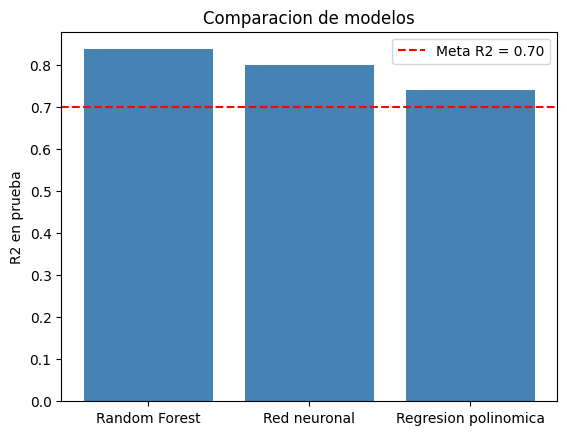

In [13]:
tabla = pd.DataFrame(resultados)

print("R2 por conjunto")
display(tabla.pivot(index="Modelo", columns="Conjunto", values="R2").round(4))

print("Metricas en prueba")
prueba = tabla[tabla["Conjunto"] == "Prueba"].sort_values("R2", ascending=False)
display(prueba.round(4))

plt.bar(prueba["Modelo"], prueba["R2"], color="steelblue")
plt.axhline(0.70, color="red", linestyle="--", label="Meta R2 = 0.70")
plt.ylabel("R2 en prueba")
plt.title("Comparacion de modelos")
plt.legend()
plt.show()

# **Celda 12: Variables más importantes (Random Forest)**
Muestra cuánto usó el bosque cada variable para predecir el precio.

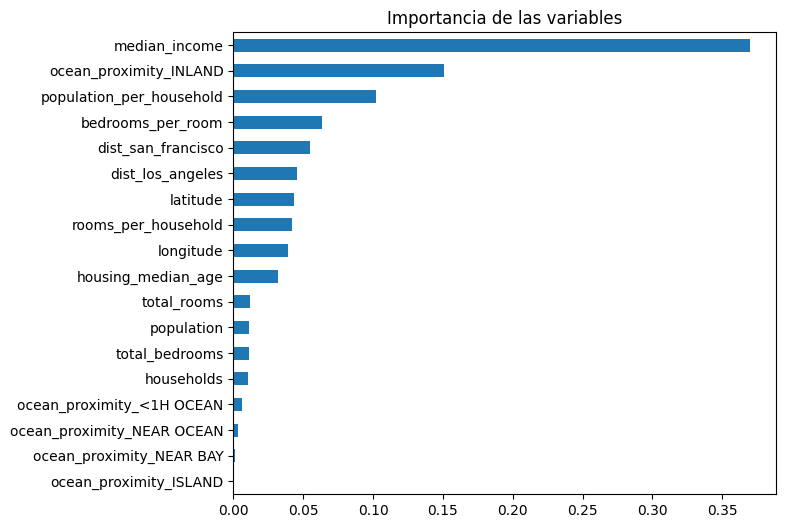

In [ ]:
importancia = pd.Series(bosque.feature_importances_, index=X_train_prep.columns)
importancia.sort_values().plot(kind="barh", figsize=(7, 6), title="Importancia de las variables")
plt.show()

In [ ]:
# Mostrar los resultados tabulados usando un DataFrame de pandas para las conclusiones
tabla_conclusiones = prueba[['Modelo', 'R2', 'RMSE', 'Error relativo %']].copy()
tabla_conclusiones.columns = ['Modelo', 'R² (Prueba)', 'RMSE (USD)', 'Error Relativo (%)']

# Formatear la visualización del DataFrame de pandas
tabla_conclusiones['R² (Prueba)'] = tabla_conclusiones['R² (Prueba)'].round(4)
tabla_conclusiones['RMSE (USD)'] = tabla_conclusiones['RMSE (USD)'].apply(lambda x: f"{x:,.2f}")
tabla_conclusiones['Error Relativo (%)'] = tabla_conclusiones['Error Relativo (%)'].round(2).astype(str) + " %"

print("Conclusiones de la celda 11")
display(tabla_conclusiones)

# **Conclusiones**
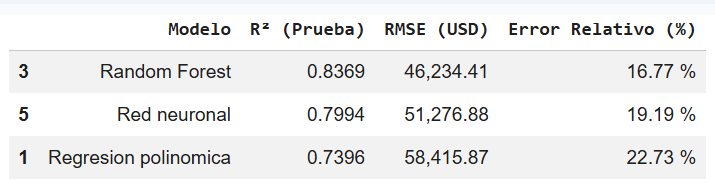
- **Random Forest** suele ser el mejor: capta relaciones no lineales sin necesidad de escalar ni transformar, aunque su R² de entrenamiento muy alto indica algo de sobreajuste.
- **Red neuronal:** buen equilibrio entre entrenamiento y prueba.
- **Regresión polinómica:** el modelo más simple; supera 0.70 gracias a las nuevas características y a los términos de grado 2.
- La preparación de los datos (logaritmo, proporciones, distancias y **ocean_proximity** fue clave para que los tres modelos superen la meta.

### **Especificación de Variables Utilizadas**

1. Variables originales utilizadas: Se incluyeron todas las características iniciales del dataset. Estas son longitude, latitude, housing_median_age, total_rooms, total_bedrooms, population, households, median_income y ocean_proximity.

2. Variables calculadas (ingeniería de características): Se crearon cinco nuevas variables para capturar relaciones más representativas:
   - rooms_per_household (promedio de habitaciones por hogar).
   - bedrooms_per_room (proporción de dormitorios respecto al total de cuartos).
   - population_per_household (promedio de habitantes por hogar).
   - dist_los_angeles (distancia a Los Ángeles).
   - dist_san_francisco (distancia a San Francisco).

3. Razón de la transformación logarítmica: Se aplicó la transformación logarítmica a variables con una distribución altamente sesgada hacia la derecha (como total_rooms, total_bedrooms, population, households, rooms_per_household y population_per_household). Esto reduce significativamente el impacto de los valores extremos o atípicos y estabiliza la varianza de los datos, lo que permite que los algoritmos de regresión y redes neuronales converjan de forma mucho más eficiente.